Jupyter Notebook for data processing and plotting for Thesis "Combining Wi-Fi TWT and MLO in OMNeT++" by Mateusz Zakrzewski

In [1]:
import pandas as pd
import numpy as np
import glob
import os
import math
import re
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# ── Simulation parameters ─────────────────────────────────────────────────────
NODE_COUNT   = 4      # fixed node count per CSV file
N_RUNS       = 10     # number of simulation repetitions
Z_95         = 1.98   # z-score for 95 % confidence interval
MS_CONV      = 1000   # seconds → milliseconds conversion factor
FONT         = 18     # base font size for all plots

# ── Scheduler display-name mapping ────────────────────────────────────────────
SCHEDULER_NAME_MAP = {
    'SymmetricalScheduler':  'Symmetrical',
    'NoScheduler':   'No scheduler',
    'AsymmetricalScheduler': 'Asymmetrical',
    'CrossSymmetricalScheduler': 'Cross-symmetrical',
}

SCHEDULER_COLORS = {
    'Symmetrical':       sns.color_palette('tab10')[0],
    'Asymmetrical':      sns.color_palette('tab10')[1],
    'Cross-symmetrical': sns.color_palette('tab10')[2],
    'No scheduler':      sns.color_palette('tab10')[3],
}

CYCLE_COLORS = {
    0:     sns.color_palette('tab10')[4],
    8192:  sns.color_palette('tab10')[0],
    16384: sns.color_palette('tab10')[1],
    32768: sns.color_palette('tab10')[2],
    65536: sns.color_palette('tab10')[3],
}

ROLE_COLORS = {
    'Sender':   sns.color_palette('tab10')[0],
    'Receiver': sns.color_palette('tab10')[1],
}

NODE_COUNTS     = [4]
CYCLE_DURATIONS = [8192, 16384, 32768, 65536]
SCHEDULERS      = ['Symmetrical', 'Asymmetrical', 'Cross-symmetrical']

# Maps metric column names to y-axis labels
METRIC_LABELS = {
    'latency_entry':    'Latency [ms]',
    'latency_transmit': 'Latency (transmit→exit) [ms]',
    'jitter_entry':     'Jitter [ms]',
    'jitter_transmit':  'Jitter (transmit) [ms]',
}

## Data Preparation

In [3]:
def map_pairwise(host):
    """Map a host name to its sender/receiver pair label, e.g. 'host3' -> 'host3_4'."""
    num  = int(host.replace('host', ''))
    base = num if num % 2 == 1 else num - 1
    return f'host{base}_{base + 1}'


def sender_or_receiver(host_name):
    """Return 'Sender' for odd-numbered hosts, 'Receiver' for even-numbered hosts."""
    num = int(host_name.replace('host', ''))
    return 'Sender' if num % 2 == 1 else 'Receiver'

In [4]:
def prep_df(df):
    """
    Transform a raw packet-log DataFrame into per-packet latency/jitter rows.

    Expected input columns: module, type, iface, value, name
                            (module_iface is dropped if present).
    Output columns: module, name, latency_entry, latency_transmit,
                    jitter_entry, jitter_transmit, exit_timestamp.
    """
    df = df.copy()
    if 'module_iface' in df.columns:
        df = df.drop('module_iface', axis=1)

    df = df[(df['type'] != 'latency') & (df['module'] != 'accessPoint')]
    df['module'] = df['module'].apply(map_pairwise)

    df_entry    = df[df['type'] == 'entry'].copy()
    df_exit     = df[df['type'] == 'exit'].copy()
    df_transmit = (df[df['type'] == 'transmit']
                   .copy()
                   .drop_duplicates(subset=['module', 'name'], keep='first'))

    df_exit  = df_exit[df_exit['iface'] == 'umac'].copy()
    df_entry = (df_entry[df_entry['iface'] == 'umac']
                .copy()
                .drop_duplicates(subset=['module', 'name'], keep='first'))

    out = df_exit[['module', 'name']].copy()
    out['exit_timestamp'] = df_exit['value'].values
    out = out.merge(
        df_entry[['module', 'name', 'value']].rename(columns={'value': 'entry_timestamp'}),
        how='inner', on=['name', 'module'],
    )
    out = out.merge(
        df_transmit[['module', 'name', 'value']].rename(columns={'value': 'transmit_timestamp'}),
        how='inner', on=['name', 'module'],
    )

    out['latency_entry']    = out['exit_timestamp'] - out['entry_timestamp']
    out['latency_transmit'] = out['exit_timestamp'] - out['transmit_timestamp']
    out['packet_number']    = out['name'].str.split('-').str[-1].astype(int)
    out = out.sort_values(by=['module', 'packet_number'])

    out['jitter_entry']    = np.abs(out.groupby('module')['latency_entry'].diff().fillna(0))
    out['jitter_transmit'] = np.abs(out.groupby('module')['latency_transmit'].diff().fillna(0))

    return out[['module', 'name', 'latency_entry', 'latency_transmit',
                'jitter_entry', 'jitter_transmit', 'exit_timestamp']]

In [5]:
def extract_scheduler(filename):
    """
    Return the display name of the scheduler used in a simulation run.
    Files whose basename starts with 'NoTWT' are the unscheduled baseline.
    Files with a 'sched=<name>' token are mapped via SCHEDULER_NAME_MAP.
    Anything else that cannot be identified also maps to 'No scheduler'.
    """
    if os.path.basename(filename).startswith('NoTWT'):
        return 'No scheduler'
    match = re.search(r'sched=([^,\-]+)', filename)
    return SCHEDULER_NAME_MAP.get(match.group(1), 'No scheduler') if match else 'No scheduler'

def extract_cycle(filename):
    match = re.search(r'cycl=(\d+)', filename)
    return int(match.group(1)) * 1024 if match else 0   # NoTWT files have no cycle → 0

def extract_run_num(filename):
    match = re.search(r'#(\d+)', filename)
    return int(match.group(1)) if match else -1

def extract_interval(filename):
    match = re.search(r'interval=(\d+)', filename)
    return int(match.group(1)) if match else -1

def extract_link(filename):
    match = re.search(r'slo=(\d+)', filename)
    return int(match.group(1)) if match else -1

## Load Datasets

In [6]:
def load_packet_files(files):
    """
    Read packet-log CSVs, run prep_df, attach metadata columns, and concatenate.
    Returns an empty DataFrame if the file list is empty.
    """
    dfs = []
    for file in files:
        raw = pd.read_csv(file, delimiter=',')
        df  = prep_df(raw)
        df['scheduler']  = extract_scheduler(file)
        df['cycle']      = extract_cycle(file)
        df['node_count'] = NODE_COUNT
        df['sim_run']    = os.path.basename(file).split('_')[0]
        df['run_num']    = extract_run_num(file)
        df['interval']   = extract_interval(file)
        df['link']       = extract_link(file)
        for col in ['latency_entry', 'latency_transmit', 'jitter_entry', 'jitter_transmit']:
            df[col] *= MS_CONV
        if df.empty:
            print(f'Warning: empty DataFrame for {file}')
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def load_energy_files(files):
    """
    Read energy CSVs, attach metadata columns, and concatenate.
    Returns an empty DataFrame if the file list is empty.

    sim_run uses the same split('_')[0] rule as load_packet_files so that
    the two DataFrames can be merged on sim_run without mismatches.
    """
    dfs = []
    for file in files:
        df = pd.read_csv(file, delimiter=',')
        df['host']         = df['host'].str.split('.').str[1]
        df['role']         = df['host'].apply(sender_or_receiver)
        df['value']        = df['value'].abs()
        df['scheduler']    = extract_scheduler(file)
        df['if_scheduler'] = 'Scheduler' if extract_scheduler(file) != 'No scheduler' else 'No scheduler'
        df['cycle']        = extract_cycle(file)
        df['node_count']   = NODE_COUNT
        df['sim_run']      = os.path.basename(file).split('_')[0]
        df['run_num']      = extract_run_num(file)
        df['interval']     = extract_interval(file)
        if df.empty:
            print(f'Warning: empty DataFrame for {file}')
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

## File Loading

In [7]:
packet_csvs = glob.glob('CSVs/*packetLog.csv')
energy_csvs = glob.glob('CSVs/*energy_data.csv')

# NoTWT* files are the unscheduled baseline — they are loaded together with
# TWT* files so that every plot automatically has access to both.
df_packets = load_packet_files(packet_csvs)
df_energy  = load_energy_files(energy_csvs)

## Plot Helpers

In [8]:
def ci(std, n=N_RUNS):
    """95 % confidence interval half-width. Propagates NaN gracefully for single runs."""
    return Z_95 * std / math.sqrt(n)


def apply_grid_style(axs):
    """Apply uniform tick styling to a flat array of axes."""
    for ax in axs:
        ax.tick_params(axis='x', which='major', labelsize=FONT - 2, width=2, length=6)
        ax.tick_params(axis='x', which='minor', labelsize=FONT - 2, width=1.5, length=4)
        ax.tick_params(axis='y', which='major', labelsize=FONT - 2, width=2, length=6)
        ax.tick_params(axis='y', which='minor', labelsize=FONT - 2, width=1.5, length=4)


def add_shared_legend(fig, handles, labels, ncol=4, title=None, y=0.03):
    """Place a centred legend below the figure. No-ops if handles is empty."""
    if not handles:
        return
    fig.legend(
        handles, labels,
        loc='lower center', ncol=ncol,
        frameon=True, fancybox=True, shadow=True,
        title=title, bbox_to_anchor=(0.5, y), fontsize=FONT,
    )


def _no_data_label(ax, msg='No data available'):
    """Show a centred italic message and disable axes in an empty subplot."""
    ax.text(0.5, 0.5, msg, transform=ax.transAxes,
            ha='center', va='center', fontsize=FONT - 2, color='gray', style='italic')
    ax.set_axis_off()


def compute_percentile_stats(df, group_cols, metric, percentile):
    """
    Compute per-run percentile, then aggregate mean ± std across runs.

    Parameters
    ----------
    df          : source DataFrame
    group_cols  : columns that define a logical experiment condition
    metric      : numeric column to aggregate
    percentile  : percentile value 0–100 (floats like 99.9 are supported)

    Returns a DataFrame with columns: *group_cols, 'mean', 'std'.
    Returns an empty DataFrame (with correct columns) if input is empty.
    """
    if df.empty or metric not in df.columns:
        return pd.DataFrame(columns=group_cols + ['mean', 'std'])

    pct_label  = f'p{percentile}'
    run_groups = group_cols + ['run_num']
    df_runs = (
        df.groupby(run_groups)[metric]
          .agg([(pct_label, lambda x, p=percentile: x.quantile(p / 100))])
          .reset_index()
    )
    return (
        df_runs.groupby(group_cols)[pct_label]
               .agg([('mean', 'mean'), ('std', 'std')])
               .reset_index()
    )

## Plot Functions

In [9]:
def plot_validate(df, metric):
    """Time-series plot of a single metric for host1_2 — sanity check."""
    df = df[(df['module'] == 'host1_2') & (df['exit_timestamp'].between(5, 10))].copy()
    if df.empty:
        print(f'plot_validate: no data for metric={metric}')
        return
    ylabel = 'Latency' if 'latency' in metric else 'Jitter'

    plt.figure(figsize=(10, 8))
    sns.set_style('whitegrid')
    sns.set_context('notebook', font_scale=1.3)
    plt.tick_params(axis='both', which='major', labelsize=FONT, width=2, length=6)
    plt.plot(df['exit_timestamp'], df[metric],
             marker='o', markersize=5, color=SCHEDULER_COLORS['Symmetrical'])
    plt.xlabel('Packet reception timestamp [s]', fontsize=FONT)
    plt.ylabel(f'{ylabel} [ms]', fontsize=FONT)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'plots/{metric}_validation.png')
    plt.show()

In [10]:
def plot_cdf(df, cycle=0):
    """Single-panel CDF of latency_entry per scheduler for one cycle duration."""
    df_f = df[df['cycle'] == cycle]
    print(df['cycle'])
    if df_f.empty:
        print(f'plot_cdf: no data for cycle={cycle}')
        return

    plt.figure(figsize=(5, 6))
    sns.set_style('whitegrid')
    sns.set_context('notebook', font_scale=1.2)
    plt.tick_params(axis='both', which='major', labelsize=FONT, width=2, length=6)

    ax = sns.ecdfplot(data=df_f, x='latency_entry', hue='scheduler',
                      stat='proportion', palette=SCHEDULER_COLORS, linewidth=2.5)
    plt.xlabel('Latency [ms]', fontsize=FONT)
    plt.ylabel('Cumulative Probability', fontsize=FONT)
    plt.grid(True, alpha=0.3)
    sns.move_legend(ax, loc='upper center', bbox_to_anchor=(0.5, -0.15),
                    frameon=True, fancybox=True, shadow=True,
                    title='Scheduler Types', fontsize=FONT)
    plt.tight_layout()
    plt.savefig(f'plots/cdf_cyc{cycle}.png')
    plt.show()

In [11]:
def plot_metric_grid(df, metric, percentile=99, node_counts=None,
                     interval=None, link=None, exclude=None, filename=None):
    """
    2x2 grid: percentile of *metric* vs. cycle duration, one subplot per node count.

    Parameters
    ----------
    df          : packet DataFrame from load_packet_files
    metric      : column name, e.g. 'latency_entry', 'jitter_entry'
    percentile  : which percentile to show (0-100, floats allowed)
    node_counts : list of four node-count values; defaults to NODE_COUNTS
    interval    : optional — keep only rows with df['interval'] == interval
    link        : optional — keep only rows with df['link'] == link
    exclude     : list of (scheduler, cycle) tuples to drop before plotting
    filename    : output path; auto-derived from metric + percentile if omitted
    """
    if df.empty:
        print(f'plot_metric_grid: DataFrame is empty, skipping.')
        return

    if node_counts is None:
        node_counts = NODE_COUNTS
    ylabel   = METRIC_LABELS.get(metric, metric)
    filename = filename or f'plots/{metric}_grid_p{percentile}.png'

    fig, axs = plt.subplots(2, 2, figsize=(11, 12))
    axs = axs.flatten()
    sns.set_style('whitegrid')
    sns.set_context('notebook', font_scale=1.0)
    apply_grid_style(axs)

    for i, nodes in enumerate(node_counts):
        df_f = df.copy()
        if interval is not None:
            df_f = df_f[df_f['interval'] == interval]
        if link is not None:
            df_f = df_f[df_f['link'] == link]
        df_f = df_f[df_f['node_count'] == nodes]
        if exclude:
            for sched, cyc in exclude:
                df_f = df_f[~((df_f['scheduler'] == sched) & (df_f['cycle'] == cyc))]

        if df_f.empty:
            _no_data_label(axs[i], f'No data\n({nodes} nodes)')
            continue

        df_stats = compute_percentile_stats(
            df_f, ['scheduler', 'cycle', 'node_count'], metric, percentile
        )
        if df_stats.empty:
            _no_data_label(axs[i], f'No data\n({nodes} nodes)')
            continue

        baseline = df_stats[df_stats['scheduler'] == 'No scheduler']
        if not baseline.empty:
            b_mean = baseline['mean'].iloc[0]
            b_ci   = ci(baseline['std'].iloc[0])
            axs[i].axhline(y=b_mean, color=SCHEDULER_COLORS['No scheduler'],
                           linewidth=2, label='No scheduler')
            axs[i].axhspan(b_mean - b_ci, b_mean + b_ci,
                           color=SCHEDULER_COLORS['No scheduler'], alpha=0.2)

        for scheduler in SCHEDULERS:
            sdata = df_stats[df_stats['scheduler'] == scheduler]
            if sdata.empty:
                continue
            cycles = sdata['cycle'].values
            means  = sdata['mean'].values
            cis    = ci(sdata['std'].values)
            color  = SCHEDULER_COLORS[scheduler]
            axs[i].plot(cycles, means, color=color, linewidth=2,
                        label=scheduler, marker='s', markersize=6)
            axs[i].errorbar(cycles, means, yerr=cis, color=color,
                            alpha=0.7, capsize=4, capthick=1.5, fmt='none')

        axs[i].set_xlabel('Cycle Duration [\u03bcs]', fontsize=FONT)
        axs[i].set_ylabel(ylabel, fontsize=FONT)
        axs[i].set_title(f'{nodes} nodes', fontsize=FONT)

        unique_cycles = sorted(df_stats['cycle'][df_stats['cycle'] != 0].unique())
        if unique_cycles:
            axs[i].set_xticks(unique_cycles)
            axs[i].set_xlim(min(unique_cycles) - 1000, max(unique_cycles) + 1000)
        axs[i].grid(alpha=0.3)

    # Collect handles from the first subplot that has any
    all_handles, all_labels = [], []
    for ax in axs:
        h, l = ax.get_legend_handles_labels()
        if h:
            all_handles, all_labels = h, l
            break
    add_shared_legend(fig, all_handles, all_labels, ncol=4)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15, top=0.95)
    plt.savefig(filename)
    plt.show()

In [12]:
def plot_cdf_grid(df, cycles=None):
    """2x2 grid of CDF plots for latency_entry, one subplot per cycle duration."""
    if df.empty:
        print('plot_cdf_grid: DataFrame is empty, skipping.')
        return

    if cycles is None:
        cycles = CYCLE_DURATIONS

    fig, axs = plt.subplots(2, 2, figsize=(10, 12))
    axs = axs.flatten()
    sns.set_style('whitegrid')
    sns.set_context('notebook', font_scale=1.1)
    apply_grid_style(axs)

    for i, cycle in enumerate(cycles):
        df_f = df[df['cycle'] == cycle].copy()
        if cycle == 8192:
            df_f = df_f[df_f['scheduler'] != 'Asymmetrical']  # exception: no data

        if df_f.empty:
            _no_data_label(axs[i], f'No data\n({cycle} \u03bcs)')
            continue

        sns.ecdfplot(data=df_f, x='latency_entry', hue='scheduler',
                     stat='proportion', palette=SCHEDULER_COLORS,
                     linewidth=2.0, ax=axs[i])
        title = f'{cycle} \u03bcs cycle' if cycle != 0 else 'Non-scheduled scenario'
        axs[i].set_title(title, fontsize=FONT)
        axs[i].set_xlabel('Latency [ms]', fontsize=FONT)
        axs[i].set_ylabel('Cumulative Probability', fontsize=FONT)
        axs[i].grid(True, alpha=0.3)
        leg = axs[i].get_legend()
        if leg:
            leg.remove()

    # Only include schedulers that actually appear in the data
    present = df['scheduler'].unique()
    custom_handles = [plt.Line2D([0], [0], color=SCHEDULER_COLORS[s], lw=2.5)
                      for s in SCHEDULERS if s in present]
    custom_labels  = [s for s in SCHEDULERS if s in present]
    add_shared_legend(fig, custom_handles, custom_labels, ncol=4, title='Scheduler Types')
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15, top=0.95)
    plt.savefig('plots/cdf_grid.png')
    plt.show()

In [13]:
def plot_throughput_grid(df):
    """2x2 grid: packet count vs node count, one subplot per scheduler type."""
    if df.empty:
        print('plot_throughput_grid: DataFrame is empty, skipping.')
        return

    all_schedulers = ['No scheduler'] + SCHEDULERS

    fig, axs = plt.subplots(2, 2, figsize=(11, 12))
    axs = axs.flatten()
    sns.set_style('whitegrid')
    sns.set_context('notebook', font_scale=1.4)
    apply_grid_style(axs)

    for i, scheduler in enumerate(all_schedulers):
        df_f = df[df['scheduler'] == scheduler].copy()
        if df_f.empty:
            _no_data_label(axs[i], f'No data\n({scheduler})')
            continue

        df_counts = (
            df_f.groupby(['sim_run', 'scheduler', 'cycle', 'node_count'])
                .size().reset_index(name='packet_count')
        )
        df_stats = (
            df_counts.groupby(['scheduler', 'cycle', 'node_count'])['packet_count']
                     .agg([('mean', 'mean'), ('std', 'std')])
                     .reset_index()
        )

        for cycle, group in df_stats.groupby('cycle'):
            color = CYCLE_COLORS.get(cycle, 'gray')
            label = f'{cycle} \u03bcs' if cycle != 0 else 'No cycle'
            axs[i].plot(group['node_count'], group['mean'],
                        color=color, linestyle='-', marker='o', markersize=8,
                        linewidth=2.0, markeredgecolor='black', markeredgewidth=1,
                        alpha=0.9, label=label)
            axs[i].errorbar(group['node_count'], group['mean'],
                            yerr=ci(group['std'].values),
                            color=color, alpha=0.7, capsize=4, capthick=1.5, fmt='none')

        axs[i].set_xlabel('Node Count', fontsize=FONT)
        axs[i].set_ylabel('Packet Count', fontsize=FONT)
        axs[i].set_title(scheduler, fontsize=FONT)
        unique_nc = sorted(df_counts['node_count'].unique())
        if unique_nc:
            axs[i].set_xticks(unique_nc)
            axs[i].set_xlim(min(unique_nc) - 2, max(unique_nc) + 2)
        axs[i].grid(alpha=0.3)

    # Only include cycles that appear in the data
    present_cycles = sorted(df['cycle'].unique())
    custom_handles = [plt.Line2D([0], [0], color=CYCLE_COLORS.get(c, 'gray'), lw=2.5)
                      for c in present_cycles]
    custom_labels  = ['No cycle' if c == 0 else f'{c} \u03bcs' for c in present_cycles]
    add_shared_legend(fig, custom_handles, custom_labels, ncol=5,
                      title='Cycle duration [\u03bcs]')
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15, top=0.95)
    plt.savefig('plots/throughput_grid.png')
    plt.show()

In [14]:
def plot_energy_grid(df_packets, df_energy):
    """2x2 grid: energy per packet vs node count, one subplot per scheduler type."""
    if df_packets.empty or df_energy.empty:
        print('plot_energy_grid: one or both DataFrames are empty, skipping.')
        return

    all_schedulers = ['Symmetrical', 'Asymmetrical', 'Cross-symmetrical', 'No scheduler']

    fig, axs = plt.subplots(2, 2, figsize=(11, 12))
    axs = axs.flatten()
    for ax in axs:
        ax.yaxis.offsetText.set_fontsize(FONT - 4)
    sns.set_style('whitegrid')
    sns.set_context('notebook', font_scale=1.1)
    apply_grid_style(axs)

    for i, scheduler in enumerate(all_schedulers):
        pkt  = df_packets[df_packets['scheduler'] == scheduler].copy()
        enrg = df_energy[df_energy['scheduler'] == scheduler].copy()

        if pkt.empty or enrg.empty:
            _no_data_label(axs[i], f'No data\n({scheduler})')
            continue

        pkt_counts = (
            pkt.groupby(['sim_run', 'scheduler', 'node_count'])
               .size().reset_index(name='packet_count')
        )
        energy_per_sim = (
            enrg.groupby(['role', 'scheduler', 'node_count', 'sim_run'])['value']
                .mean().reset_index()
        )
        merged = energy_per_sim.merge(pkt_counts, on=['sim_run', 'scheduler', 'node_count'])
        if merged.empty:
            _no_data_label(axs[i], f'No data\n({scheduler})')
            continue

        merged['energy_per_packet'] = merged['value'] / merged['packet_count']
        df_stats = (
            merged.groupby(['scheduler', 'node_count', 'role'])['energy_per_packet']
                  .agg([('mean', 'mean'), ('std', 'std')])
                  .reset_index()
        )

        for role, group in df_stats.groupby('role'):
            color = ROLE_COLORS.get(role, 'gray')
            group = group.sort_values('node_count')
            axs[i].plot(group['node_count'], group['mean'],
                        color=color, linestyle='-', marker='o', markersize=7,
                        linewidth=2.0, markeredgecolor='black', markeredgewidth=1,
                        alpha=0.9, label=role)
            axs[i].errorbar(group['node_count'], group['mean'],
                            yerr=ci(group['std'].values),
                            color=color, alpha=0.5, capsize=3, capthick=1, fmt='none')

        axs[i].set_xlabel('Node Count', fontsize=FONT)
        axs[i].set_ylabel('Energy per Packet [J]', fontsize=FONT)
        axs[i].set_title(scheduler, fontsize=FONT)
        axs[i].set_xticks(NODE_COUNTS)
        axs[i].set_xlim(min(NODE_COUNTS) - 2, max(NODE_COUNTS) + 2)
        axs[i].grid(alpha=0.3)
        leg = axs[i].get_legend()
        if leg:
            leg.remove()

    custom_handles = [plt.Line2D([0], [0], color=ROLE_COLORS[r], lw=2.0)
                      for r in ['Sender', 'Receiver']]
    add_shared_legend(fig, custom_handles, ['Sender', 'Receiver'],
                      ncol=2, title='STA Role')
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15, top=0.95)
    plt.savefig('plots/energy_grid_by_nodecount_mean.png', dpi=300, bbox_inches='tight')
    plt.show()

In [15]:
def compare_schedulers(df_stats):
    """
    Print a pivot comparison of mean values across schedulers.
    Only computes differences for scheduler pairs that are both present in the data.
    Returns (cross_sym_vs_sym_mean, cross_sym_vs_asym_mean), using None for missing pairs.
    """
    if df_stats.empty:
        print('compare_schedulers: no data')
        return None, None

    pivot = (
        df_stats.pivot_table(index=['cycle', 'node_count'],
                             columns='scheduler', values='mean')
                .reset_index()
                .rename_axis(None, axis=1)
    )

    cols = pivot.columns
    if 'Symmetrical' in cols and 'Cross-symmetrical' in cols:
        pivot['CrossSymVsSym']  = ((pivot['Symmetrical']  - pivot['Cross-symmetrical']) / pivot['Cross-symmetrical'] * 100).round(2)
    if 'Asymmetrical' in cols and 'Cross-symmetrical' in cols:
        pivot['CrossSymVsAsym'] = ((pivot['Asymmetrical'] - pivot['Cross-symmetrical']) / pivot['Cross-symmetrical'] * 100).round(2)
    if 'Asymmetrical' in cols and 'Symmetrical' in cols:
        pivot['SymVsAsym']      = ((pivot['Asymmetrical'] - pivot['Symmetrical'])        / pivot['Symmetrical']        * 100).round(2)

    print(pivot.to_string())
    cross_vs_sym  = pivot['CrossSymVsSym'].mean()  if 'CrossSymVsSym'  in pivot.columns else None
    cross_vs_asym = pivot['CrossSymVsAsym'].mean() if 'CrossSymVsAsym' in pivot.columns else None
    return cross_vs_sym, cross_vs_asym

## Generate Plots

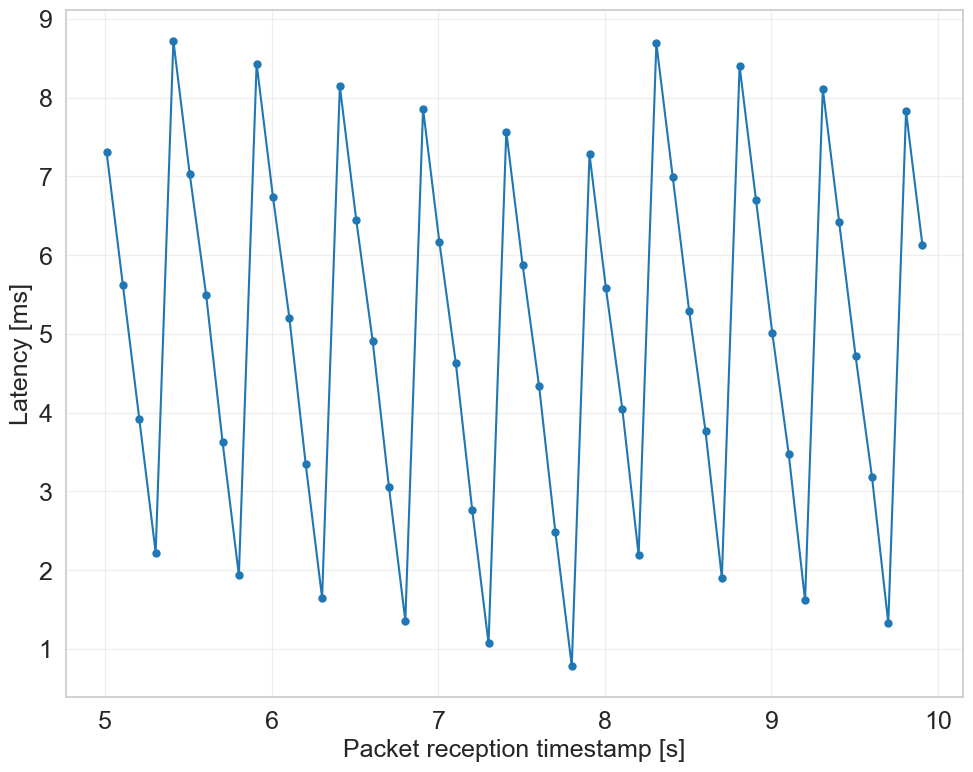

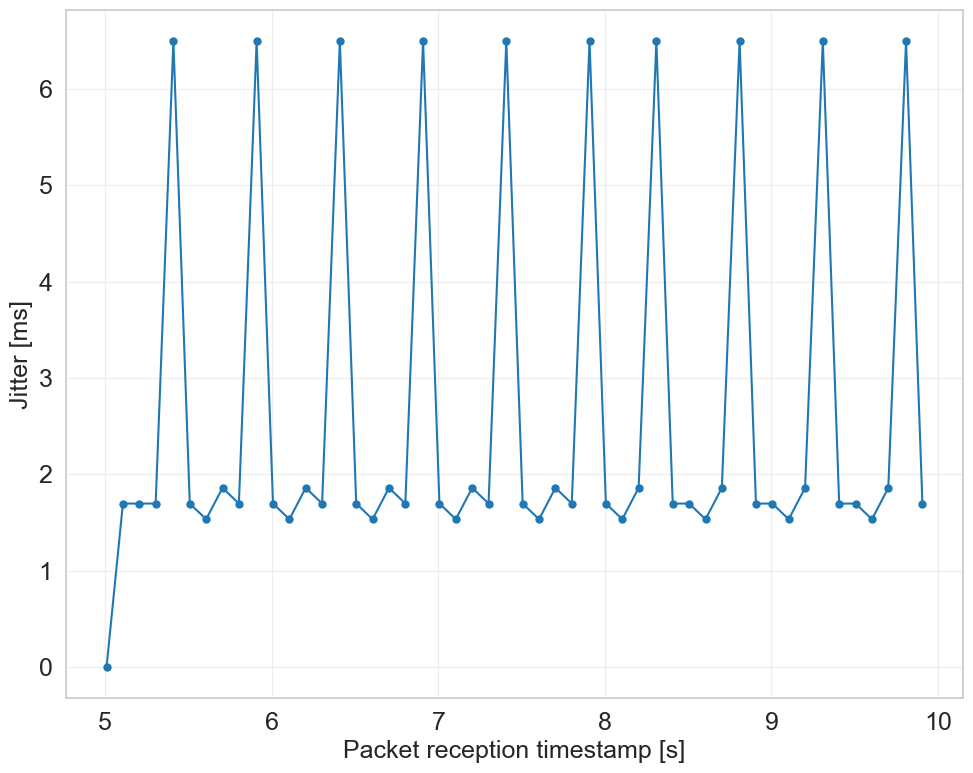

In [16]:
df_single = df_packets[
    df_packets['sim_run'] == 'TWT-interval=100,cycl=8,sched=SymmetricalScheduler-#0'
]
plot_validate(df_single, 'latency_entry')
plot_validate(df_single, 'jitter_entry')

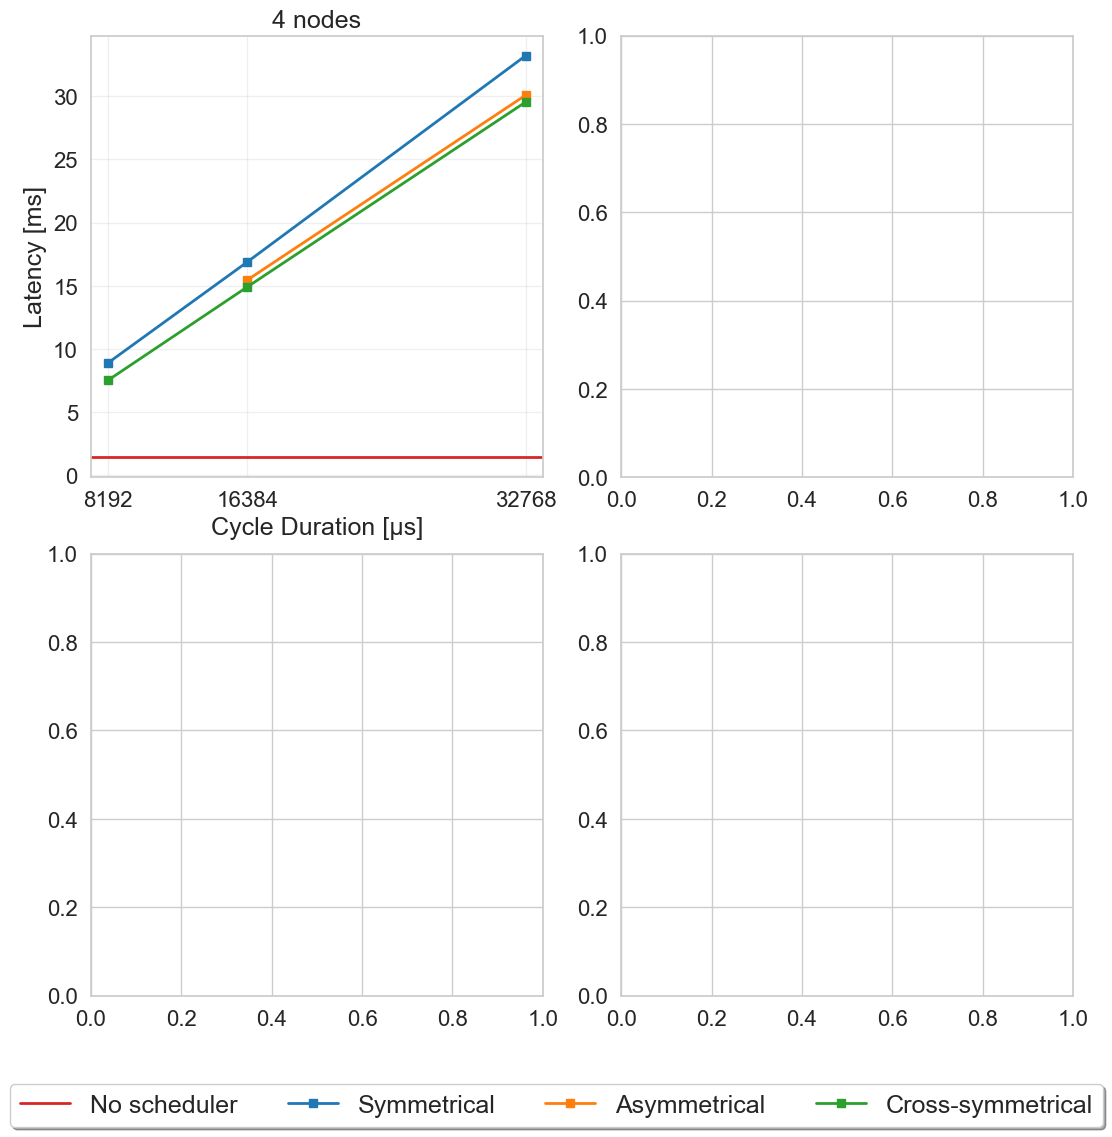

In [17]:
# p99 latency entry — Asymmetrical at 8192 µs excluded (no valid data point)
plot_metric_grid(
    df_packets, metric='latency_entry', percentile=99,
    exclude=[('Asymmetrical', 8192)],
)

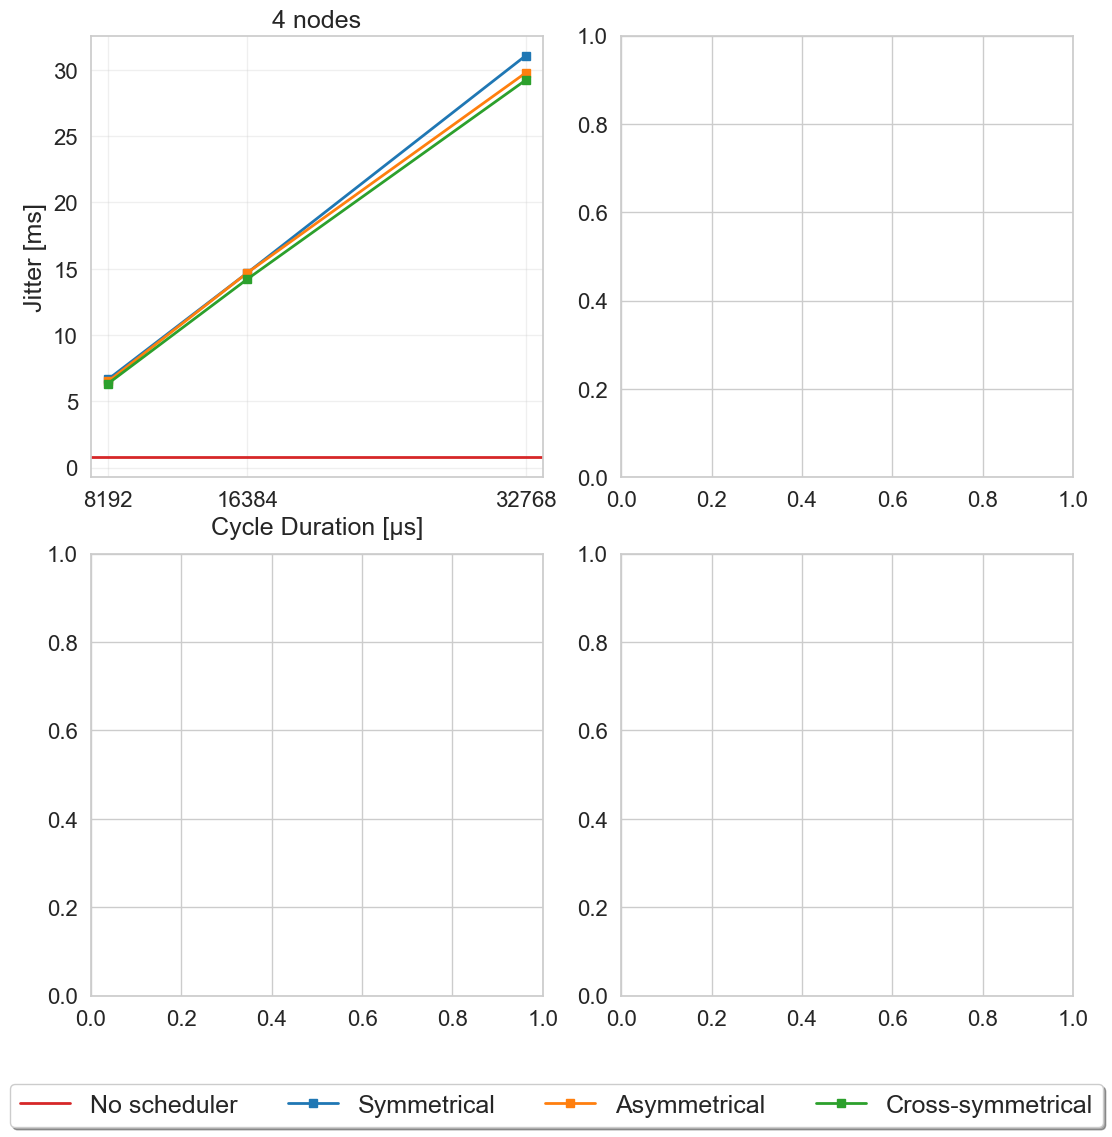

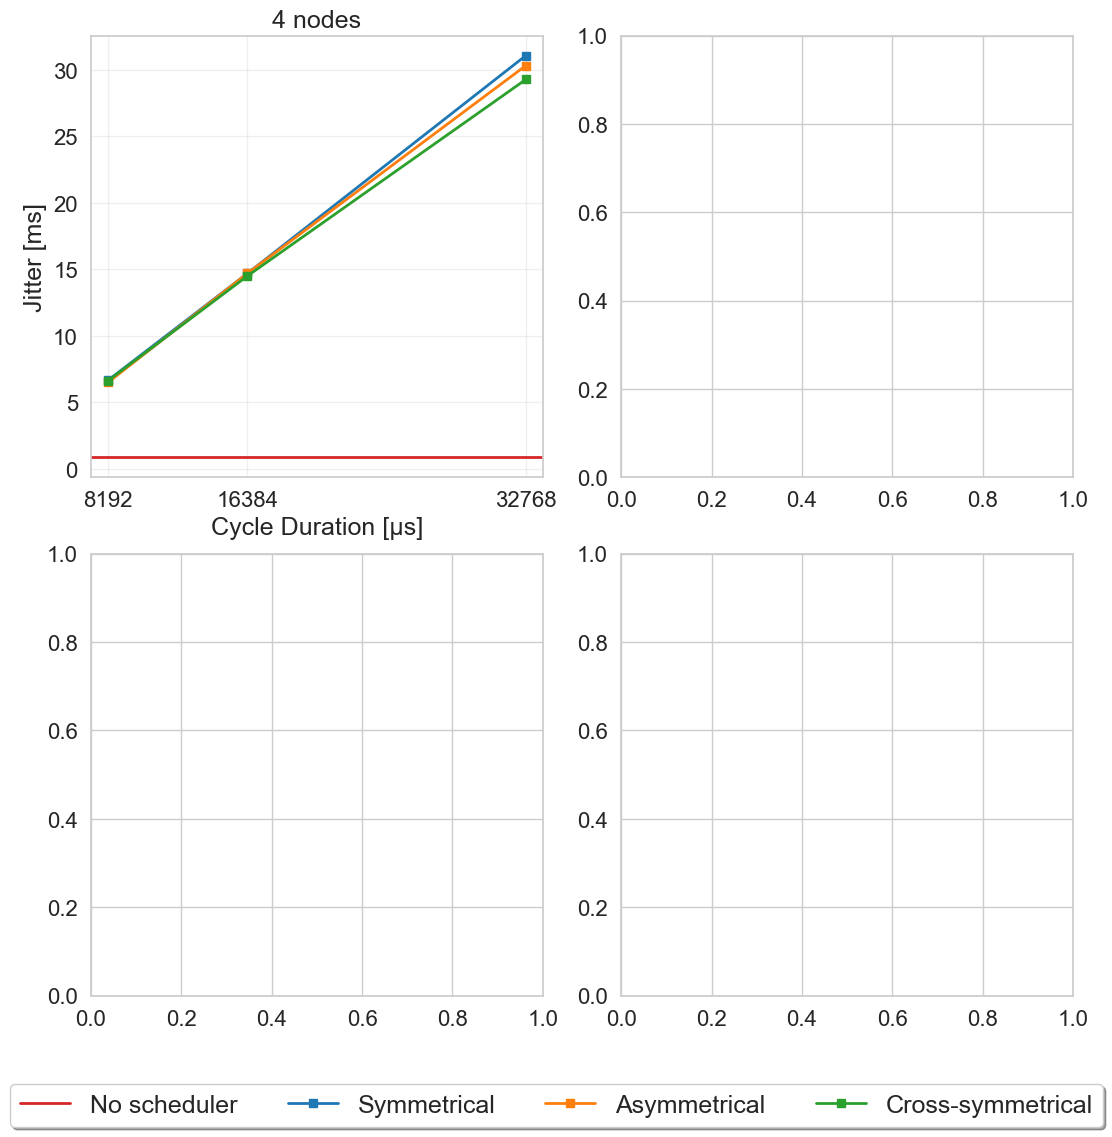

In [18]:
# p99 and p99.9 jitter
plot_metric_grid(df_packets, metric='jitter_entry', percentile=99)
plot_metric_grid(df_packets, metric='jitter_entry', percentile=99.9)

0          0
1          0
2          0
3          0
4          0
        ... 
1895    8192
1896    8192
1897    8192
1898    8192
1899    8192
Name: cycle, Length: 1900, dtype: int64


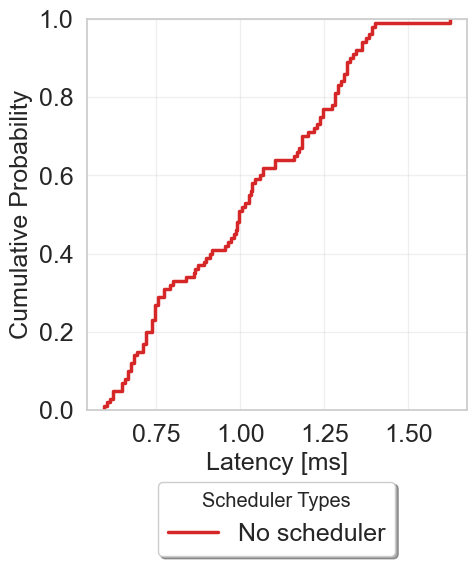

In [19]:
plot_cdf(df_packets, cycle=0) # for No Scheduler

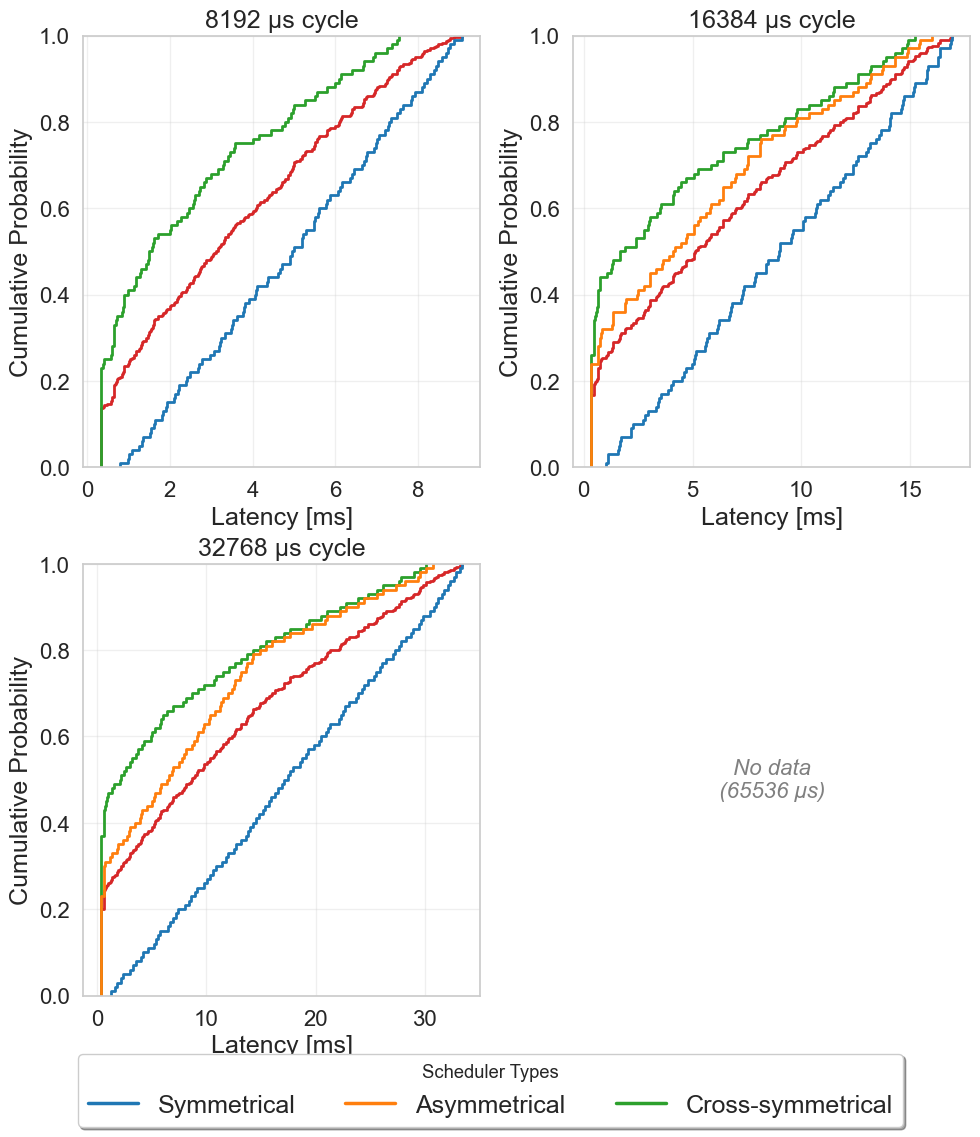

In [20]:
plot_cdf_grid(df_packets)

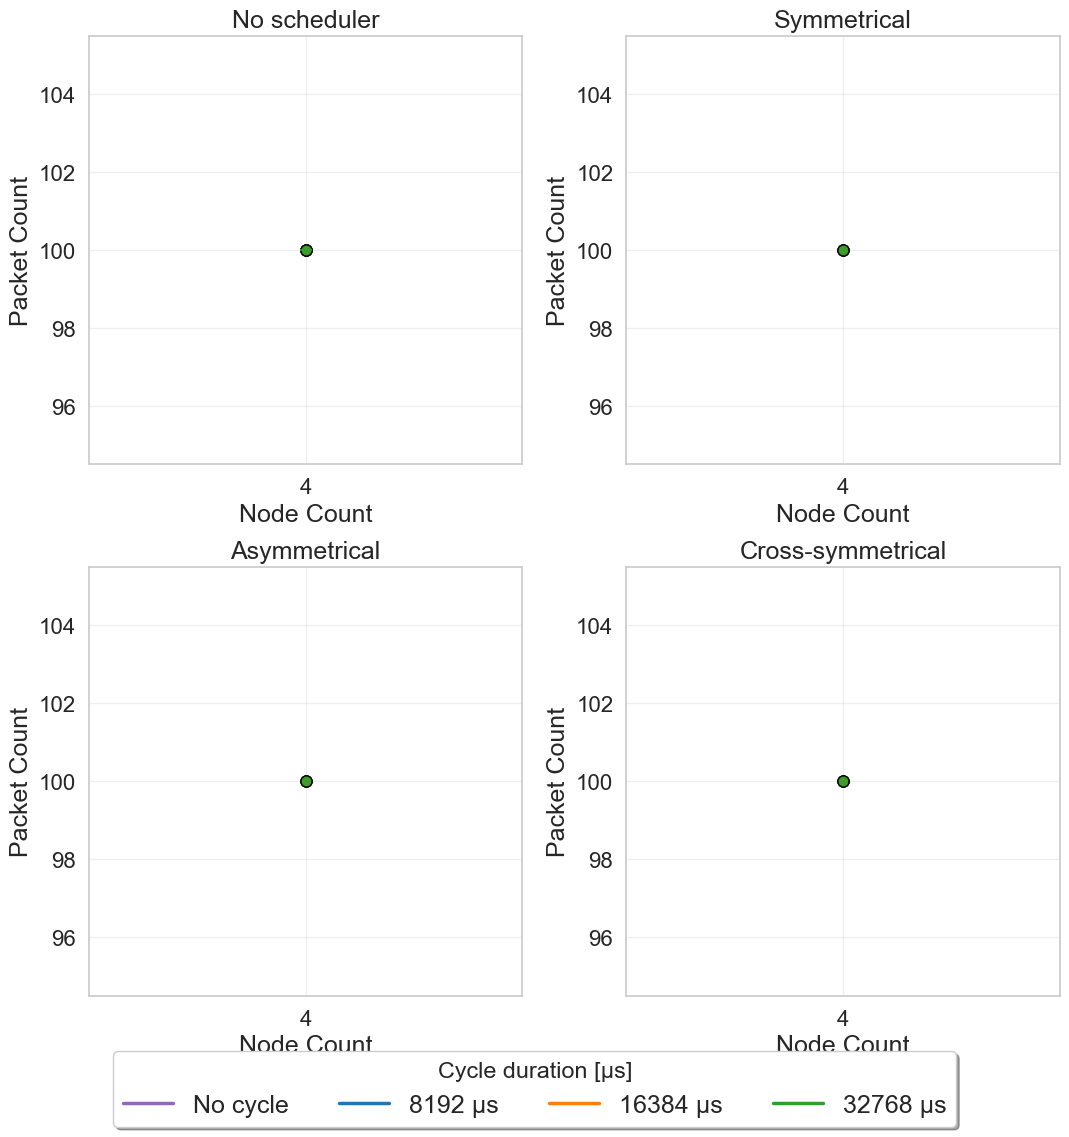

In [21]:
plot_throughput_grid(df_packets)

## Data Analysis

In [22]:
# Average p99 latency improvement across schedulers (excluding 8192 µs Asymmetrical)
df_stats = compute_percentile_stats(
    df_packets,
    group_cols=['scheduler', 'cycle', 'node_count'],
    metric='latency_entry',
    percentile=99,
)
compare_schedulers(
    df_stats[(df_stats['cycle'] != 8192) & (df_stats['scheduler'] != 'No scheduler')]
)

   cycle  node_count  Asymmetrical  Cross-symmetrical  Symmetrical  CrossSymVsSym  CrossSymVsAsym  SymVsAsym
0  16384           4     15.448639          14.902666    16.880707          13.27            3.66      -8.48
1  32768           4     30.105151          29.560618    33.234002          12.43            1.84      -9.41


(12.85, 2.75)

In [23]:
# Average p99.9 jitter improvement across schedulers
df_stats = compute_percentile_stats(
    df_packets,
    group_cols=['scheduler', 'cycle', 'node_count'],
    metric='jitter_entry',
    percentile=99.9,
)
compare_schedulers(df_stats[df_stats['scheduler'] != 'No scheduler'])

   cycle  node_count  Asymmetrical  Cross-symmetrical  Symmetrical  CrossSymVsSym  CrossSymVsAsym  SymVsAsym
0   8192           4      6.496000           6.626842     6.659064           0.49           -1.97      -2.45
1  16384           4     14.688000          14.493981    14.688000           1.34            1.34      -0.00
2  32768           4     30.318808          29.274796    31.072000           6.14            3.57      -2.42


(2.6566666666666667, 0.98)

In [24]:
# Throughput improvement relative to no-scheduler baseline
df_counts = (
    df_packets.groupby(['sim_run', 'scheduler', 'cycle', 'node_count'])
              .size().reset_index(name='packet_count')
)
df_stats = (
    df_counts.groupby(['scheduler', 'cycle', 'node_count'])['packet_count']
             .agg([('mean', 'mean'), ('std', 'std')])
             .reset_index()
)
pivot = (
    df_stats.pivot_table(index=['cycle', 'node_count'], columns='scheduler', values='mean')
            .reset_index().rename_axis(None, axis=1)
)

if 'No scheduler' in pivot.columns:
    no_sched_ref = (pivot[pivot['cycle'] == 0][['node_count', 'No scheduler']]
                    .rename(columns={'No scheduler': '_baseline'}))
    pivot = pivot.merge(no_sched_ref, on='node_count', how='left')
    pivot['No scheduler'] = pivot['No scheduler'].fillna(pivot['_baseline'])
    pivot.drop('_baseline', axis=1, inplace=True)

    for sched in SCHEDULERS:
        if sched in pivot.columns:
            pivot[f'{sched}_improvement_pct'] = (
                (pivot[sched] - pivot['No scheduler']) / pivot['No scheduler'] * 100
            ).round(2)
else:
    print('Throughput comparison: no baseline (No scheduler) data — improvement % not computed.')

pivot

,cycle,node_count,Asymmetrical,Cross-symmetrical,No scheduler,Symmetrical,Symmetrical_improvement_pct,Asymmetrical_improvement_pct,Cross-symmetrical_improvement_pct
0,0,4,NaN,NaN,100.0,NaN,NaN,NaN,NaN
1,8192,4,100.0,100.0,100.0,100.0,0.0,0.0,0.0
2,16384,4,100.0,100.0,100.0,100.0,0.0,0.0,0.0
3,32768,4,100.0,100.0,100.0,100.0,0.0,0.0,0.0


In [25]:
# Energy savings per packet relative to no-scheduler baseline
df_pkt  = df_packets.copy()
df_enrg = df_energy.copy()
df_enrg['value'] *= 1e6   # J -> µJ

pkt_counts = (
    df_pkt.groupby(['sim_run', 'scheduler', 'node_count'])
          .size().reset_index(name='packet_count')
)
energy_per_sim = (
    df_enrg.groupby(['role', 'scheduler', 'node_count', 'sim_run'])['value']
           .mean().reset_index()
)
merged = energy_per_sim.merge(pkt_counts, on=['sim_run', 'scheduler', 'node_count'])
merged['energy_per_packet'] = merged['value'] / merged['packet_count']

df_stats = (
    merged.groupby(['scheduler', 'node_count', 'role'])['energy_per_packet']
          .agg([('mean', 'mean'), ('std', 'std')])
          .reset_index()
)
pivot = (
    df_stats.pivot_table(index=['node_count', 'role'], columns='scheduler', values='mean')
            .reset_index().rename_axis(None, axis=1)
)

if 'No scheduler' not in pivot.columns:
    print('Energy savings: no baseline (No scheduler) data — savings % not computed.')
    pivot
else:
    for sched in SCHEDULERS:
        if sched in pivot.columns:
            pivot[f'{sched}_savings_pct'] = (
                (pivot['No scheduler'] - pivot[sched]) / pivot['No scheduler'] * 100
            )

    results = pd.concat([
        pivot[['node_count', 'role', sched, f'{sched}_savings_pct']]
            .rename(columns={sched: 'scheduler_energy', f'{sched}_savings_pct': 'savings_pct'})
            .assign(scheduler=sched)
        for sched in SCHEDULERS
        if sched in pivot.columns
    ])
    results.groupby(['scheduler', 'role'])['savings_pct'].mean().reset_index()

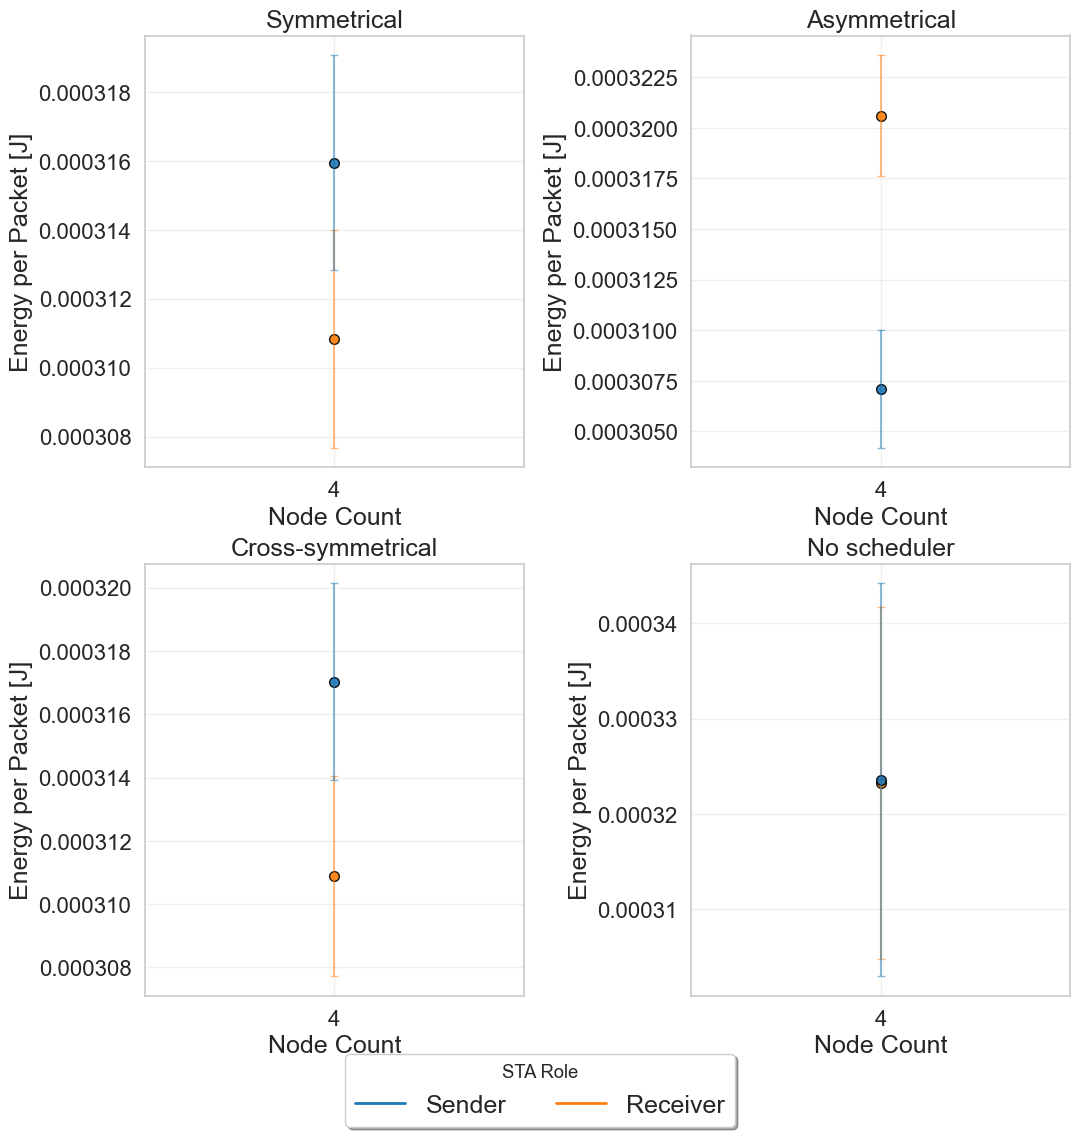

In [26]:
plot_energy_grid(df_packets, df_energy)

## Theory: Buffer Occupancy

Max buffer  Sym=0.373 MB  Asym=0.224 MB  Cross=0.160 MB
Asym  vs Sym  reduction: 40.0 %
Cross vs Sym  reduction: 57.1 %


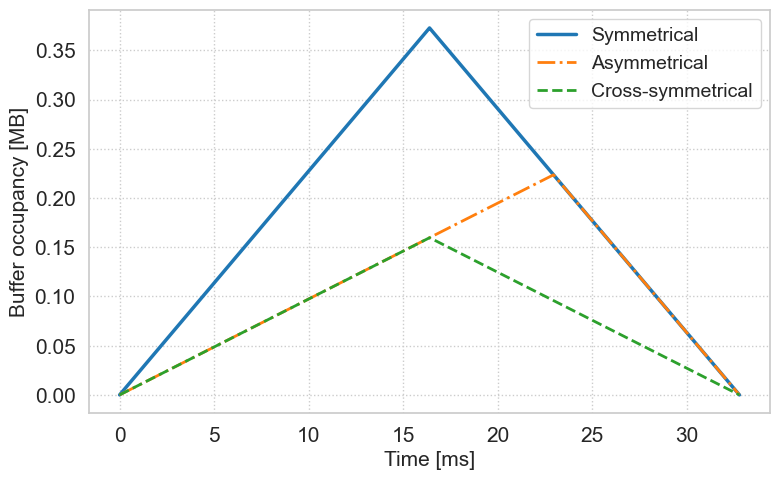

In [27]:
Link24G = 52e6
Link5G  = 130e6
cycle   = 0.032768
half    = cycle / 2

t = np.linspace(0, cycle, int(cycle / 1e-6) + 1)

# Symmetrical: both links active simultaneously
bufferSym = np.where(
    t <= half,
    (Link24G + Link5G) * t,
    np.maximum((Link24G + Link5G) * half - (Link24G + Link5G) * (t - half), 0),
)

# Asymmetrical: 70 % sleep, 30 % purge
T_s = 0.7 * cycle
fillAsym  = Link5G - Link24G
drainAsym = -(Link5G + Link24G)
bufferAsym = np.where(
    t <= T_s,
    fillAsym * t,
    np.maximum(fillAsym * T_s + drainAsym * (t - T_s), 0),
)

# Cross-symmetrical: links swap roles at midpoint
fillCross  = Link5G - Link24G
drainCross = Link24G - Link5G
bufferCross = np.where(
    t <= half,
    fillCross * t,
    np.maximum(fillCross * half + drainCross * (t - half), 0),
)

# Convert bits -> MB
bufferSym   /= 8e6
bufferAsym  /= 8e6
bufferCross /= 8e6

max_sym, max_asym, max_cross = np.max(bufferSym), np.max(bufferAsym), np.max(bufferCross)
print(f'Max buffer  Sym={max_sym:.3f} MB  Asym={max_asym:.3f} MB  Cross={max_cross:.3f} MB')
print(f'Asym  vs Sym  reduction: {(max_sym - max_asym)  / max_sym * 100:.1f} %')
print(f'Cross vs Sym  reduction: {(max_sym - max_cross) / max_sym * 100:.1f} %')

plt.figure(figsize=(8, 5))
plt.plot(t * 1000, bufferSym,   label='Symmetrical',       linewidth=2.5,
         color=SCHEDULER_COLORS['Symmetrical'],       linestyle='-')
plt.plot(t * 1000, bufferAsym,  label='Asymmetrical',      linewidth=2.0,
         color=SCHEDULER_COLORS['Asymmetrical'],      linestyle='-.')
plt.plot(t * 1000, bufferCross, label='Cross-symmetrical', linewidth=2.0,
         color=SCHEDULER_COLORS['Cross-symmetrical'], linestyle='--')
plt.xlabel('Time [ms]', fontsize=15)
plt.ylabel('Buffer occupancy [MB]', fontsize=15)
plt.grid(True, which='both', linestyle=':')
plt.legend(fontsize=14, loc='upper right')
plt.xticks(fontsize=15)
plt.yticks(fontsize=15)
plt.tight_layout()
plt.savefig('plots/bufferOccupancy.png', dpi=300, bbox_inches='tight')
plt.show()